In [3]:

import pandas as pd
import numpy as np

from google.colab import files
uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("First 5 Rows:")
display(df.head())

print("Dataset Shape (Rows, Columns):")
print(df.shape)

print("Column Names:")
print(df.columns.tolist())

print("Missing Values:")
print(df.isnull().sum())

print("Duplicate Rows:")
print(df.duplicated().sum())

print("Churn Distribution:")
print(df["Churn"].value_counts())


Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn (1).csv
First 5 Rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Dataset Shape (Rows, Columns):
(7043, 21)
Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
Duplicate Rows:
0
Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [4]:

# Check and clean data types

import pandas as pd
import numpy as np

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].replace(r"^\s*$", np.nan, regex=True)

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

print("Data Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())


Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

Missing Values:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
P

In [5]:

# Step 3: Inspect rows with missing TotalCharges

missing_rows = df[df["TotalCharges"].isnull()]

print("Number of rows with missing TotalCharges:")
print(len(missing_rows))

print("\nMissing TotalCharges details:")
display(
    missing_rows[
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)



Number of rows with missing TotalCharges:
11

Missing TotalCharges details:


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [6]:

# Step 4: Handle missing TotalCharges values

# Keep the original dataset unchanged
clean_df = df.copy()

# Fill missing TotalCharges with 0 for customers whose tenure is 0
mask = (
    clean_df["TotalCharges"].isnull()
    & (clean_df["tenure"] == 0)
)

clean_df.loc[mask, "TotalCharges"] = 0

print("Missing TotalCharges after handling:")
print(clean_df["TotalCharges"].isnull().sum())

print("\nTotal missing values in dataset:")
print(clean_df.isnull().sum().sum())

print("\nUpdated dataset shape:")
print(clean_df.shape)

print("\nRows updated:")
print(mask.sum())


Missing TotalCharges after handling:
0

Total missing values in dataset:
0

Updated dataset shape:
(7043, 21)

Rows updated:
11


In [7]:

# Step 5: Validate the cleaned dataset

print("Dataset Shape:", clean_df.shape)

print("\nDuplicate rows:")
print(clean_df.duplicated().sum())

print("\nTotal Missing Values:")
print(clean_df.isnull().sum().sum())

print("\nChurn Distribution:")
print(clean_df["Churn"].value_counts())

print("\nTotal Customers:")
print(len(clean_df))

# Check whether TotalCharges has any negative values
print("\nNegative TotalCharges:")
print((clean_df["TotalCharges"] < 0).sum())

# Check whether MonthlyCharges has any negative values
print("\nNegative MonthlyCharges:")
print((clean_df["MonthlyCharges"] < 0).sum())


Dataset Shape: (7043, 21)

Duplicate rows:
0

Total Missing Values:
0

Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Total Customers:
7043

Negative TotalCharges:
0

Negative MonthlyCharges:
0


In [8]:

# Step 6: Save and download cleaned dataset

output_file = "customer_churn_cleaned.csv"

clean_df.to_csv(output_file, index=False)

print("Cleaned dataset saved successfully!")
print("File name:", output_file)

from google.colab import files
files.download(output_file)


Cleaned dataset saved successfully!
File name: customer_churn_cleaned.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned dataset
df = pd.read_csv("customer_churn_cleaned.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nBasic statistics:")
display(df.describe(include="all"))

Dataset shape: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

Missing values:
0



,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043.000000,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,NaN,2
top,3186-AJIEK,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,NaN,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,NaN,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,2279.734304,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,2266.794470,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,0.000000,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,398.550000,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,1394.550000,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,3786.600000,NaN


Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


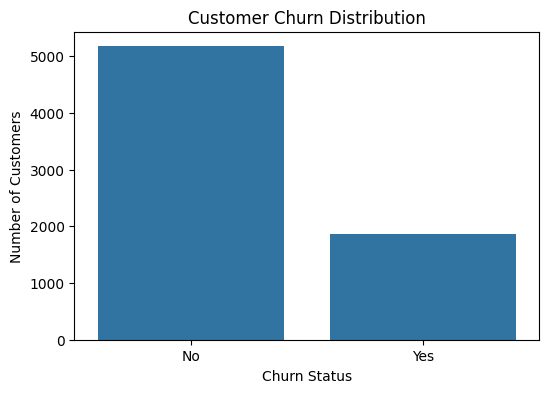

In [10]:
# Count customers in each churn category
print(df["Churn"].value_counts())

# Calculate percentages
print("\nChurn percentage:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

# Create a bar chart
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.show()

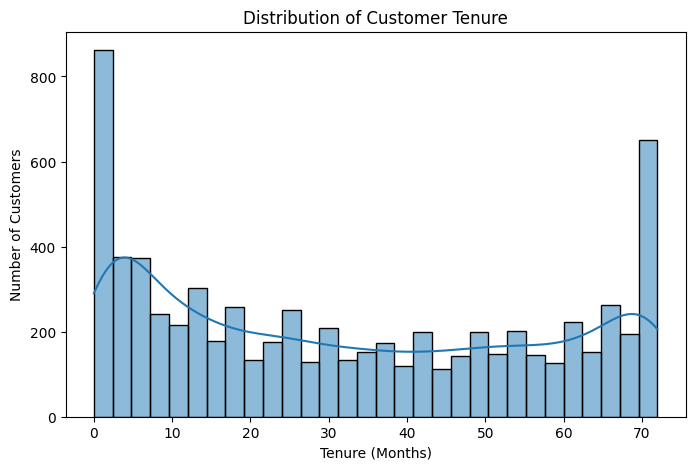

In [11]:

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="tenure", bins=30, kde=True)

plt.title("Distribution of Customer Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()


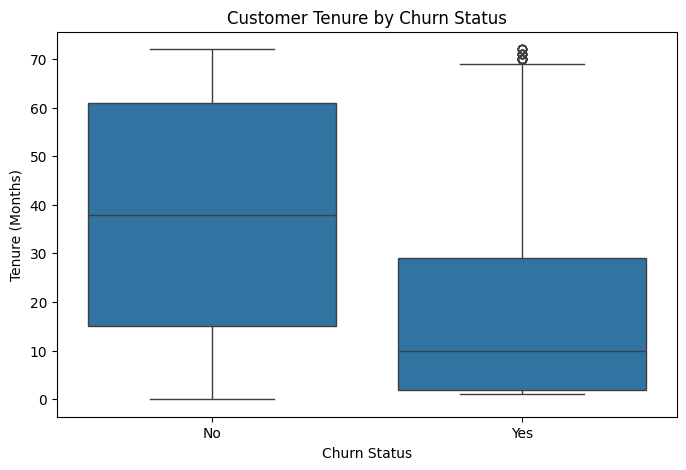

In [12]:

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="tenure")

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")

plt.show()


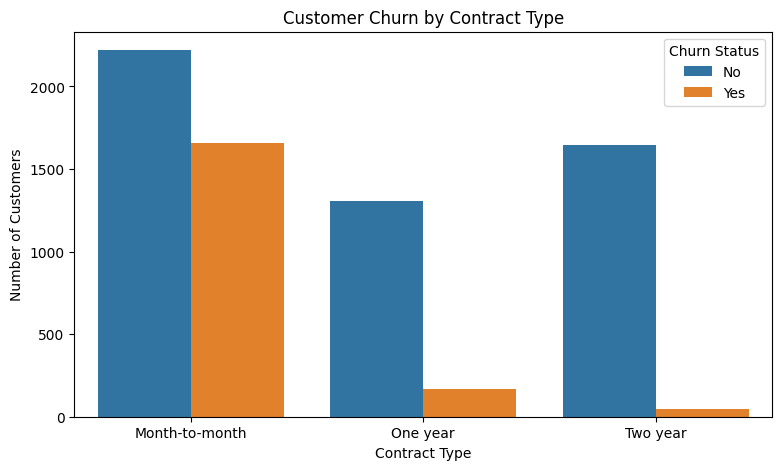

In [13]:

plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.legend(title="Churn Status")

plt.show()


Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


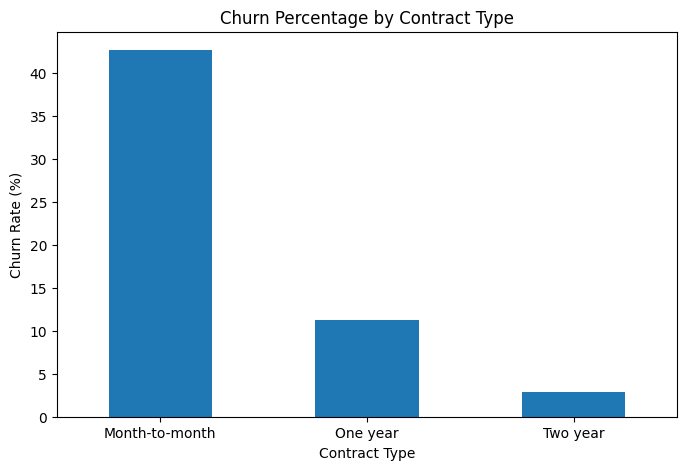

In [14]:

# Calculate churn percentage for each contract type
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn.round(2))

# Plot churn percentage
contract_churn["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Percentage by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()


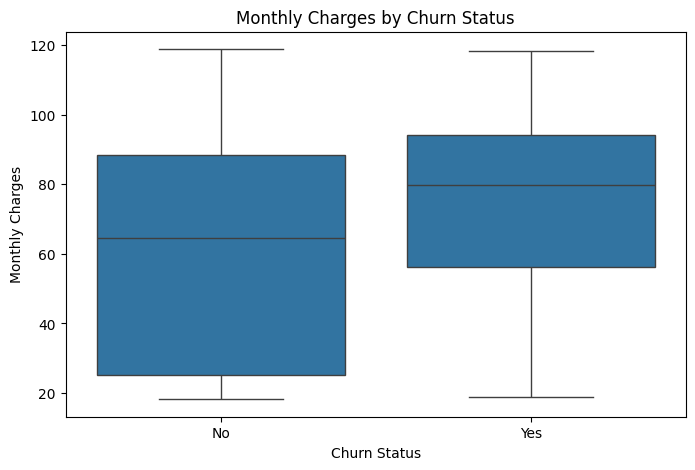

In [15]:

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")

plt.show()


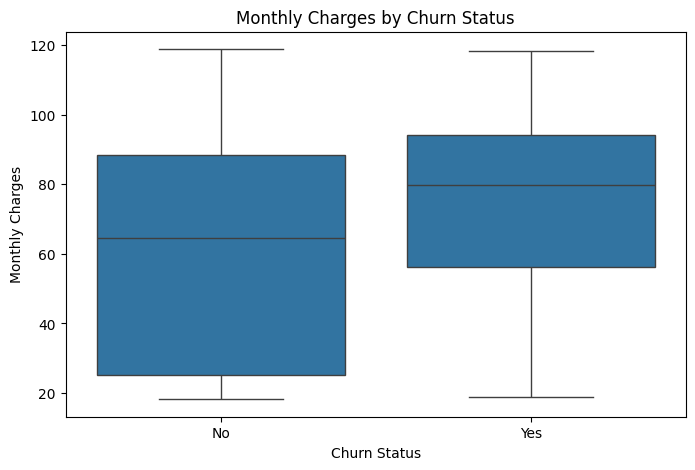

In [16]:

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")

plt.show()


In [17]:

# Select numerical columns
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

# Calculate descriptive statistics
display(df[numeric_cols].describe().round(2))

# Calculate median separately
print("\nMedian values:")
print(df[numeric_cols].median().round(2))


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80



Median values:
tenure              29.00
MonthlyCharges      70.35
TotalCharges      1394.55
dtype: float64


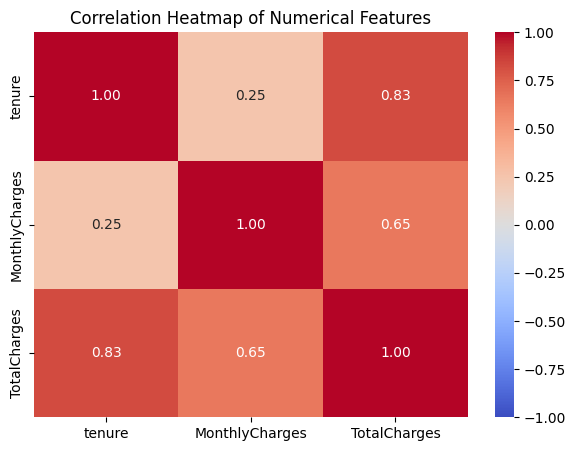

In [18]:

numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

correlation = df[numeric_cols].corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()


Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40


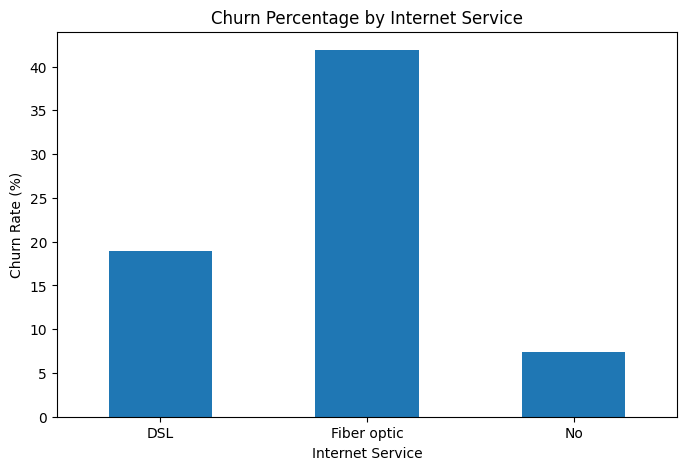

In [19]:

# Calculate churn percentage by internet service
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(internet_churn.round(2))

# Plot churn percentage
internet_churn["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Percentage by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()


Churn                   No    Yes
TechSupport                      
No                   58.36  41.64
No internet service  92.60   7.40
Yes                  84.83  15.17


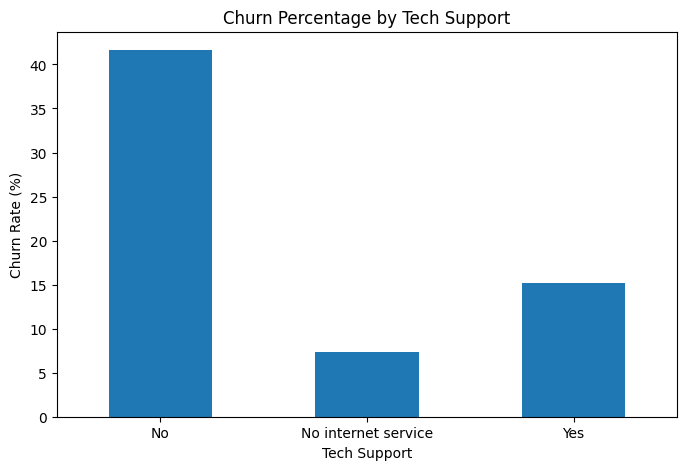

In [20]:

support_churn = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

print(support_churn.round(2))

support_churn["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Percentage by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()


In [21]:

# Final data quality checks
print("Dataset shape:", df.shape)

print("\nTotal missing values:", df.isnull().sum().sum())

print("Duplicate rows:", df.duplicated().sum())

print("\nChurn counts:")
print(df["Churn"].value_counts())

print("\nChurn percentages:")
print(
    (df["Churn"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nNumerical summary:")
display(
    df[["tenure", "MonthlyCharges", "TotalCharges"]]
    .describe()
    .round(2)
)


Dataset shape: (7043, 21)

Total missing values: 0
Duplicate rows: 0

Churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

Numerical summary:


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80
